In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import sparse
import anndata as ad
from loading import *
import muon
import scanpy as sc

#load data with AnnData
H3K27ac_ad, H3K27me3_ad = load_data_in_AnnData()

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_core\preproc.py:32: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  if Version(scanpy.__version__) < Version("1.10"):
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModifica

In [20]:
#shape of the data (H3K27ac, H3K27me3, cell types)
print(f'Shape H3K27ac : {H3K27ac_ad.X.shape}, shape H3K27me3 : {H3K27me3_ad.X.shape}, number of cell types : {len(H3K27ac_ad.obs["cell_type"].unique())}') #only the non-zero values

Shape H3K27ac : (4805, 3782654), shape H3K27me3 : (4805, 2350516), number of cell types : 24


In [21]:
#Overview of the bins (start, end, chromosome) for each histone mark
print('H3K27ac :')
print(f' - Starting of each bin: {H3K27ac_ad.var["start"].values[0:10]} \n - Ending: {H3K27ac_ad.var["end"].values[0:10]} \n - Chromosome: {H3K27ac_ad.var["chrom"].values[0:10]}')
print('H3K27me3 :')
print(f' - Starting of each bin: {H3K27me3_ad.var["start"].values[0:10]} \n - Ending: {H3K27me3_ad.var["end"].values[0:10]} \n - Chromosome: {H3K27me3_ad.var["chrom"].values[0:10]}')

H3K27ac :
 - Starting of each bin: [3003500 3006500 3007000 3008000 3009000 3010000 3011500 3012500 3013000
 3014500] 
 - Ending: [3004000 3007000 3007500 3008500 3009500 3010500 3012000 3013000 3013500
 3015000] 
 - Chromosome: ['chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1']
H3K27me3 :
 - Starting of each bin: [3005000 3005500 3011500 3021500 3028000 3028500 3033000 3033500 3048000
 3048500] 
 - Ending: [3005500 3006000 3012000 3022000 3028500 3029000 3033500 3034000 3048500
 3049000] 
 - Chromosome: ['chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1' 'chr1']


# 1. Prevalence filter

In [22]:
from preprocessing import prevalence_filtering
#filter out the bins that have non-zero values in more than 50 cells

#H3K27ac
print('Prevalence filtering for H3K27ac:')
H3K27ac_ad_filtered = prevalence_filtering(H3K27ac_ad, threshold=50)

#H3K27me3
print('Prevalence filtering for H3K27me3:')
H3K27me3_ad_filtered = prevalence_filtering(H3K27me3_ad, threshold=50)


Prevalence filtering for H3K27ac:
Number of bins with more than 50 cells having non-zero values: 43970
Prevalence filtering for H3K27me3:
Number of bins with more than 50 cells having non-zero values: 10878


### Increasing bins size (to much bins have not much non zero values, and decrease number of features)

In [23]:
from preprocessing import increase_bin_size
#Increase size of the bins to a factor x

#H3K27ac for different factors [4, 16]
H3K27ac_ad_4x = increase_bin_size(H3K27ac_ad, factor=4)
H3K27ac_ad_16x = increase_bin_size(H3K27ac_ad, factor=16)

#H3K27me3 for different factors [4, 16]
H3K27me3_ad_4x = increase_bin_size(H3K27me3_ad, factor=4)
H3K27me3_ad_16x = increase_bin_size(H3K27me3_ad, factor=16)

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [24]:
#show the decrease in the number of bins with increasing bin size for H3K27ac and H3K27me3
print(f'Shape of original H3K27ac with 500bp bin size : {H3K27ac_ad.X.shape}')
print(f' - 4x bin size (2000bp): {H3K27ac_ad_4x.X.shape}, \n - 16x bin size (8000bp): {H3K27ac_ad_16x.X.shape}')

print(f'Shape of original H3K27me3 with 500bp bin size : {H3K27me3_ad.X.shape}')
print(f' - 4x bin size (2000bp): {H3K27me3_ad_4x.X.shape},\n - 16x bin size (8000bp): {H3K27me3_ad_16x.X.shape}')


Shape of original H3K27ac with 500bp bin size : (4805, 3782654)
 - 4x bin size (2000bp): (4805, 1069311), 
 - 16x bin size (8000bp): (4805, 294215)
Shape of original H3K27me3 with 500bp bin size : (4805, 2350516)
 - 4x bin size (2000bp): (4805, 798794),
 - 16x bin size (8000bp): (4805, 257946)


In [25]:
#for each new bin size, we will filter out the bins that have non-zero values in less than 50 cells

#H3K27ac
print('Prevalence filtering for H3K27ac with different bin sizes:')

#4x H3K27ac
print(' - 4x bin size (2000bp):')
H3K27ac_4x_filt = prevalence_filtering(H3K27ac_ad_4x, threshold=50)

#16x H3K27ac
print(' - 16x bin size (8000bp):')
H3K27ac_16x_filt = prevalence_filtering(H3K27ac_ad_16x, threshold=50)

print('--------------------------------')

#H3K27me3
print('Prevalence filtering for H3K27me3 with different bin sizes:')

#4x H3K27me3
print(' - 4x bin size (2000bp):')
H3K27me3_4x_filt = prevalence_filtering(H3K27me3_ad_4x, threshold=50)

#16x H3K27me3
print(' - 16x bin size (8000bp):')
H3K27me3_16x_filt = prevalence_filtering(H3K27me3_ad_16x, threshold=50)

Prevalence filtering for H3K27ac with different bin sizes:
 - 4x bin size (2000bp):
Number of bins with more than 50 cells having non-zero values: 86509
 - 16x bin size (8000bp):
Number of bins with more than 50 cells having non-zero values: 109425
--------------------------------
Prevalence filtering for H3K27me3 with different bin sizes:
 - 4x bin size (2000bp):
Number of bins with more than 50 cells having non-zero values: 13699
 - 16x bin size (8000bp):
Number of bins with more than 50 cells having non-zero values: 20344


# 2. LSI-style (TF-IDF + SVD)

In [26]:
from dim_reduction import LSI
#LSI transformation

#H3K27ac (original filtered data, 4x and 16x increased bins data)
LSI(H3K27ac_ad_filtered, n_components=100)
LSI(H3K27ac_4x_filt, n_components=100)
LSI(H3K27ac_16x_filt, n_components=100)

#H3K27me3 (original filtered data, 4x and 16x increased bins data)
LSI(H3K27me3_ad_filtered, n_components=100)
LSI(H3K27me3_4x_filt, n_components=100)
LSI(H3K27me3_16x_filt, n_components=100)

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


In [27]:
from matplotlib import pyplot as plt
"""
#H3K27ac
var_ex_H3K27ac = H3K27ac_ad_filtered.uns['lsi']['stdev']
var_ex_H3K27ac4x = H3K27ac_4x_filt.uns['lsi']['stdev']
var_ex_H3K27ac16x = H3K27ac_16x_filt.uns['lsi']['stdev']

#H3K27me3
var_ex_H3K27me3 = H3K27me3_ad_filtered.uns['lsi']['stdev']
var_ex_H3K27me34x = H3K27me3_4x_filt.uns['lsi']['stdev']
var_ex_H3K27me316x = H3K27me3_16x_filt.uns['lsi']['stdev']

#Plot the elbow plot to visualize the explained variance ratio of the SVD components for both datasets
fig, ax = plt.subplots(2,3,figsize=(16, 8))
ax[0,0].plot(range(1, len(var_ex_H3K27ac) + 1), np.cumsum(var_ex_H3K27ac), marker='o')
ax[0,0].set_title('Original Filtered H3K27ac (cumulative)')
ax[0,0].set_xlabel('Number of Components')
ax[0,0].set_ylabel('Cumulative Explained Variance Ratio')
ax[0,0].plot(50, np.sum(var_ex_H3K27ac[:50]), marker='o', markersize=7, color='red')
ax[0,0].hlines(y=np.sum(var_ex_H3K27ac[:50]), xmin=0, xmax=50, color='red', linestyle='--')
ax[0,1].plot(range(1, len(var_ex_H3K27ac4x) + 1), np.cumsum(var_ex_H3K27ac4x), marker='o')
ax[0,1].set_title('4x bin increase of H3K27ac (cumulative)')
ax[0,1].set_xlabel('Number of Components')
ax[0,1].set_ylabel('Cumulative Explained Variance Ratio')
ax[0,1].plot(50, np.sum(var_ex_H3K27ac4x[:50]), marker='o', markersize=7, color='red')
ax[0,1].hlines(y=np.sum(var_ex_H3K27ac4x[:50]), xmin=0, xmax=50, color='red', linestyle='--')
ax[0,2].plot(range(1, len(var_ex_H3K27ac16x) + 1), np.cumsum(var_ex_H3K27ac16x), marker='o')
ax[0,2].set_title('16x bin increase of H3K27ac (cumulative)')
ax[0,2].set_xlabel('Number of Components')
ax[0,2].set_ylabel('Cumulative Explained Variance Ratio')
ax[0,2].plot(50, np.sum(var_ex_H3K27ac16x[:50]), marker='o', markersize=7, color='red')
ax[0,2].hlines(y=np.sum(var_ex_H3K27ac16x[:50]), xmin=0, xmax=50, color='red', linestyle='--')
ax[1,0].plot(range(1, len(var_ex_H3K27me3) + 1), np.cumsum(var_ex_H3K27me3), marker='o')
ax[1,0].set_title('Original Filtered H3K27me3 (cumulative)')
ax[1,0].set_xlabel('Number of Components')
ax[1,0].set_ylabel('Cumulative Explained Variance Ratio')
ax[1,0].plot(50, np.sum(var_ex_H3K27me3[:50]), marker='o', markersize=7, color='red')
ax[1,0].hlines(y=np.sum(var_ex_H3K27me3[:50]), xmin=0, xmax=50, color='red', linestyle='--')
ax[1,1].plot(range(1, len(var_ex_H3K27me34x) + 1), np.cumsum(var_ex_H3K27me34x), marker='o')
ax[1,1].set_title('4x bin increase of H3K27me3 (cumulative)')
ax[1,1].set_xlabel('Number of Components')
ax[1,1].set_ylabel('Cumulative Explained Variance Ratio')
ax[1,1].plot(50, np.sum(var_ex_H3K27me34x[:50]), marker='o', markersize=7, color='red')
ax[1,1].hlines(y=np.sum(var_ex_H3K27me34x[:50]), xmin=0, xmax=50, color='red', linestyle='--')
ax[1,2].plot(range(1, len(var_ex_H3K27me316x) + 1), np.cumsum(var_ex_H3K27me316x), marker='o')
ax[1,2].set_title('16x bin increase of H3K27me3 (cumulative)')
ax[1,2].set_xlabel('Number of Components')
ax[1,2].set_ylabel('Cumulative Explained Variance Ratio')
ax[1,2].plot(50, np.sum(var_ex_H3K27me316x[:50]), marker='o', markersize=7, color='red')
ax[1,2].hlines(y=np.sum(var_ex_H3K27me316x[:50]), xmin=0, xmax=50, color='red', linestyle='--')
fig.suptitle('Explained Variance Ratio of SVD Components (H3K27ac and H3K27me3)', fontsize=16)
plt.tight_layout()
plt.show()
"""
#don't know if we keep it or not

"\n#H3K27ac\nvar_ex_H3K27ac = H3K27ac_ad_filtered.uns['lsi']['stdev']\nvar_ex_H3K27ac4x = H3K27ac_4x_filt.uns['lsi']['stdev']\nvar_ex_H3K27ac16x = H3K27ac_16x_filt.uns['lsi']['stdev']\n\n#H3K27me3\nvar_ex_H3K27me3 = H3K27me3_ad_filtered.uns['lsi']['stdev']\nvar_ex_H3K27me34x = H3K27me3_4x_filt.uns['lsi']['stdev']\nvar_ex_H3K27me316x = H3K27me3_16x_filt.uns['lsi']['stdev']\n\n#Plot the elbow plot to visualize the explained variance ratio of the SVD components for both datasets\nfig, ax = plt.subplots(2,3,figsize=(16, 8))\nax[0,0].plot(range(1, len(var_ex_H3K27ac) + 1), np.cumsum(var_ex_H3K27ac), marker='o')\nax[0,0].set_title('Original Filtered H3K27ac (cumulative)')\nax[0,0].set_xlabel('Number of Components')\nax[0,0].set_ylabel('Cumulative Explained Variance Ratio')\nax[0,0].plot(50, np.sum(var_ex_H3K27ac[:50]), marker='o', markersize=7, color='red')\nax[0,0].hlines(y=np.sum(var_ex_H3K27ac[:50]), xmin=0, xmax=50, color='red', linestyle='--')\nax[0,1].plot(range(1, len(var_ex_H3K27ac4x

In [28]:
#highly correlated, so we need to remove it -> not help to find cell types
'''il pourrait avoir d'autre composante (e.g svd 1 highly correlate with numbre of read) svd qui sont potentielle a corr avec # read ? (Jean)'''
H3K27ac_ad_filtered.obsm['X_lsi'] = H3K27ac_ad_filtered.obsm['X_lsi'][:, 1:51]  # Remove the first component and keep the 50 components that explain the most variance
H3K27ac_4x_filt.obsm['X_lsi'] = H3K27ac_4x_filt.obsm['X_lsi'][:, 1:51]
H3K27ac_16x_filt.obsm['X_lsi'] = H3K27ac_16x_filt.obsm['X_lsi'][:, 1:51] 

H3K27me3_ad_filtered.obsm['X_lsi'] = H3K27me3_ad_filtered.obsm['X_lsi'][:, 1:51]
H3K27me3_4x_filt.obsm['X_lsi'] = H3K27me3_4x_filt.obsm['X_lsi'][:, 1:51]
H3K27me3_16x_filt.obsm['X_lsi'] = H3K27me3_16x_filt.obsm['X_lsi'][:, 1:51]

In [29]:
#Clustering using KMeans
from sklearn.cluster import KMeans

labels = H3K27ac_ad_filtered.obs['cell_type']
nbre_type = len(np.unique(labels))
kmeans = KMeans(n_clusters=nbre_type, random_state=42)

#H3K27ac

# 1) original bin size
H3K27ac_ad_filtered.obs['Kmeans'] = kmeans.fit_predict(H3K27ac_ad_filtered.obsm['X_lsi'])

# 2) 4x increased bins 
H3K27ac_4x_filt.obs['Kmeans'] = kmeans.fit_predict(H3K27ac_4x_filt.obsm['X_lsi'])

# 3) 16x increased bins
H3K27ac_16x_filt.obs['Kmeans'] = kmeans.fit_predict(H3K27ac_16x_filt.obsm['X_lsi'])

#H3K27me3

# 1) original bin size
H3K27me3_ad_filtered.obs['Kmeans'] = kmeans.fit_predict(H3K27me3_ad_filtered.obsm['X_lsi'])

# 2) 4x increased bins 
H3K27me3_4x_filt.obs['Kmeans'] = kmeans.fit_predict(H3K27me3_4x_filt.obsm['X_lsi'])

# 3) 16x increased bins
H3K27me3_16x_filt.obs['Kmeans'] = kmeans.fit_predict(H3K27me3_16x_filt.obsm['X_lsi'])

In [30]:
#clustering with leiden
# 1) first compute neighbor distance matrix 
# 2) second compute leiden (need the distance matrix)

#H3K27ac

#original bin size
sc.pp.neighbors(H3K27ac_ad_filtered, n_neighbors=20, use_rep='X_lsi', key_added='nn_lsi')
sc.tl.leiden(H3K27ac_ad_filtered, resolution=1, key_added='leiden', neighbors_key='nn_lsi')

#4x increased bins
sc.pp.neighbors(H3K27ac_4x_filt, n_neighbors=20, use_rep='X_lsi', key_added='nn_lsi')
sc.tl.leiden(H3K27ac_4x_filt, resolution=1, key_added='leiden', neighbors_key='nn_lsi')

#16x increased bins
sc.pp.neighbors(H3K27ac_16x_filt, n_neighbors=20, use_rep='X_lsi', key_added='nn_lsi')
sc.tl.leiden(H3K27ac_16x_filt, resolution=1, key_added='leiden', neighbors_key='nn_lsi')

#H3K27me3

#original bin size
sc.pp.neighbors(H3K27me3_ad_filtered, n_neighbors=20, use_rep='X_lsi', key_added='nn_lsi')
sc.tl.leiden(H3K27me3_ad_filtered, resolution=1, key_added='leiden', neighbors_key='nn_lsi')

#4x increased bins
sc.pp.neighbors(H3K27me3_4x_filt, n_neighbors=20, use_rep='X_lsi', key_added='nn_lsi')
sc.tl.leiden(H3K27me3_4x_filt, resolution=1, key_added='leiden', neighbors_key='nn_lsi')

#16x increased bins
sc.pp.neighbors(H3K27me3_16x_filt, n_neighbors=20, use_rep='X_lsi', key_added='nn_lsi')
sc.tl.leiden(H3K27me3_16x_filt, resolution=1, key_added='leiden', neighbors_key='nn_lsi')

In [31]:
#preform umap for visualization (also need neighbor distance matrix)

#H3K27ac

#original
sc.tl.umap(H3K27ac_ad_filtered, neighbors_key='nn_lsi')

#4x increased bins 
sc.tl.umap(H3K27ac_4x_filt, neighbors_key='nn_lsi')

#16x increased bins
sc.tl.umap(H3K27ac_16x_filt, neighbors_key='nn_lsi')

#original
sc.tl.umap(H3K27me3_ad_filtered, neighbors_key='nn_lsi')

#4x increased bins 
sc.tl.umap(H3K27me3_4x_filt, neighbors_key='nn_lsi')

#16x increased bins
sc.tl.umap(H3K27me3_16x_filt, neighbors_key='nn_lsi')

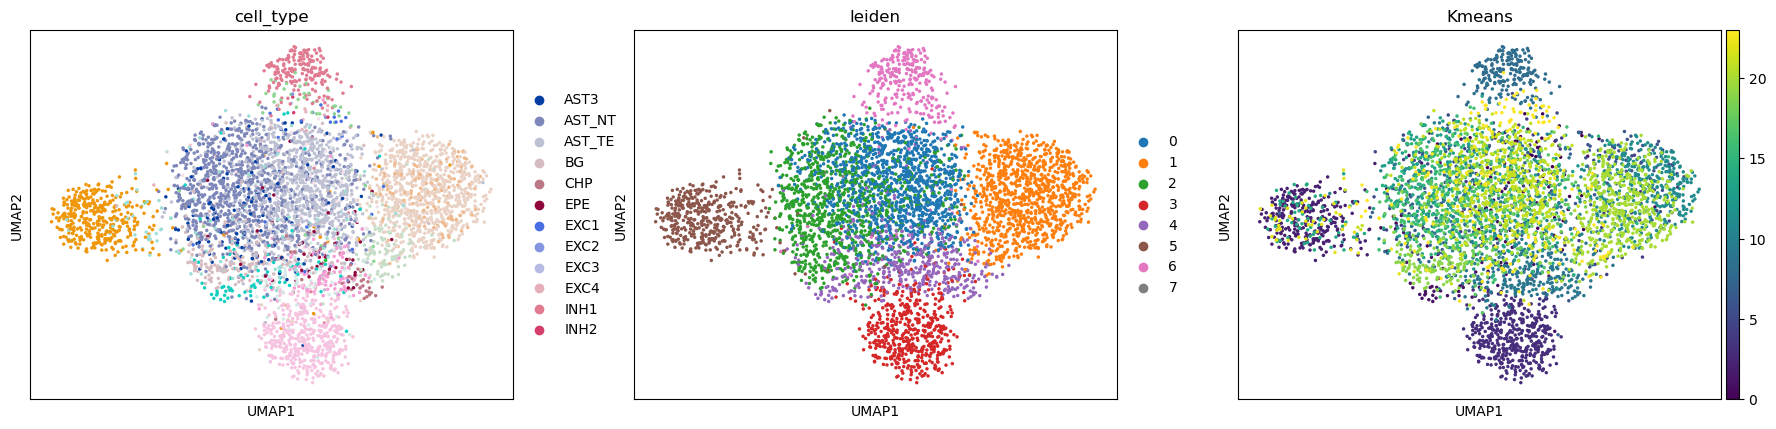

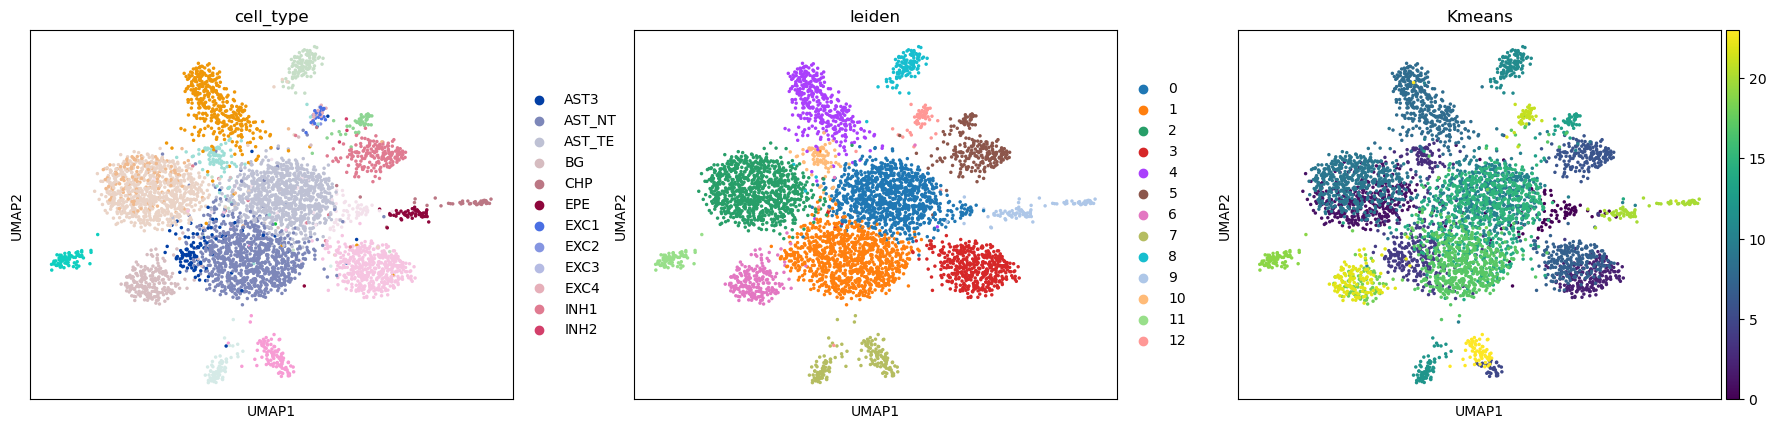

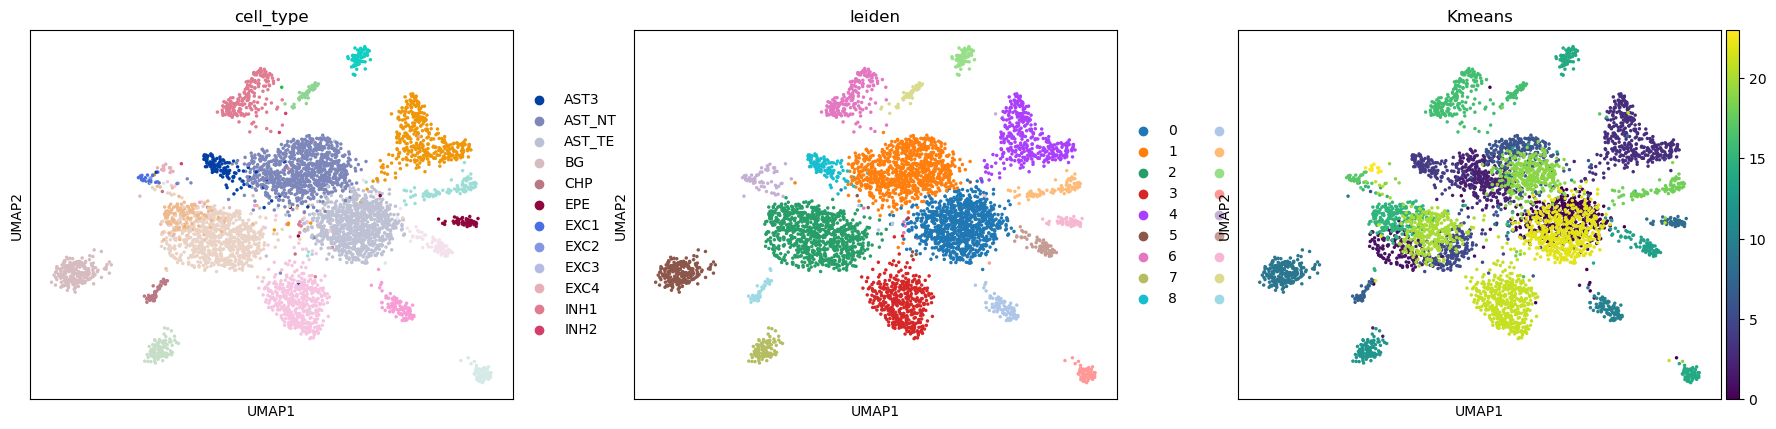

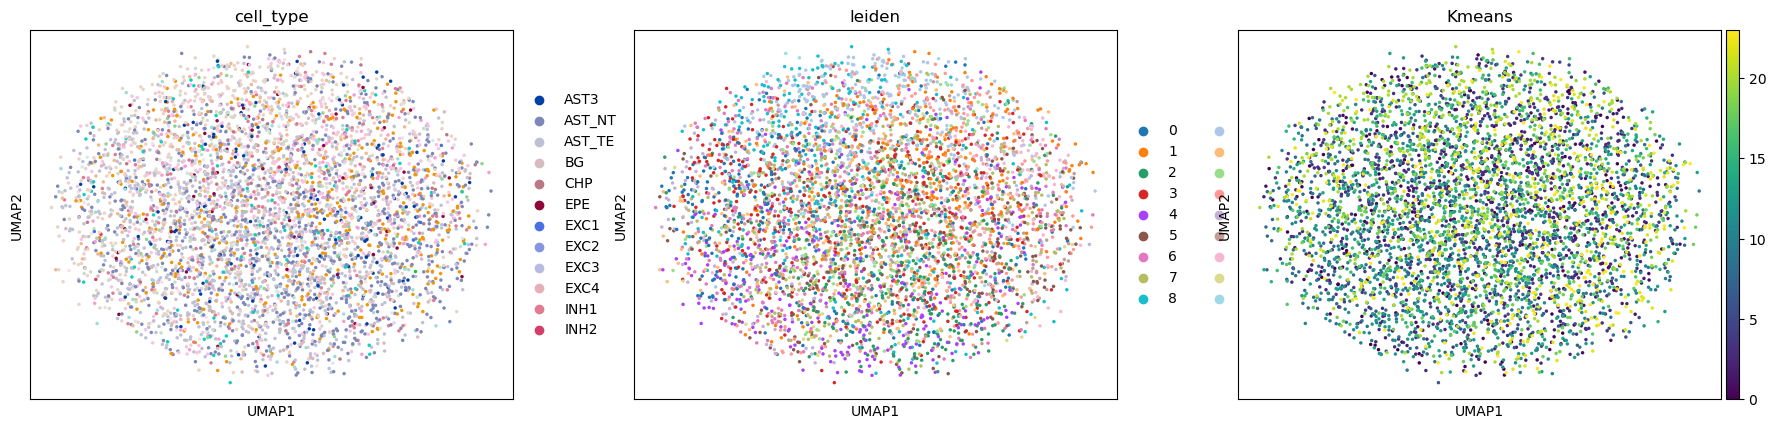

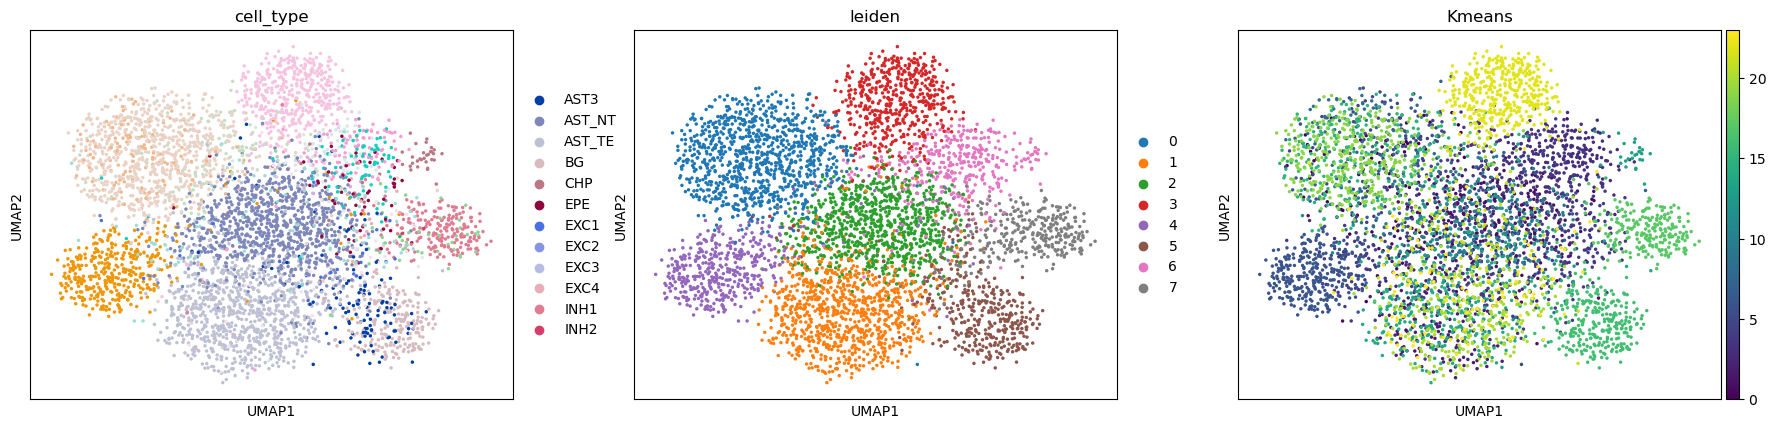

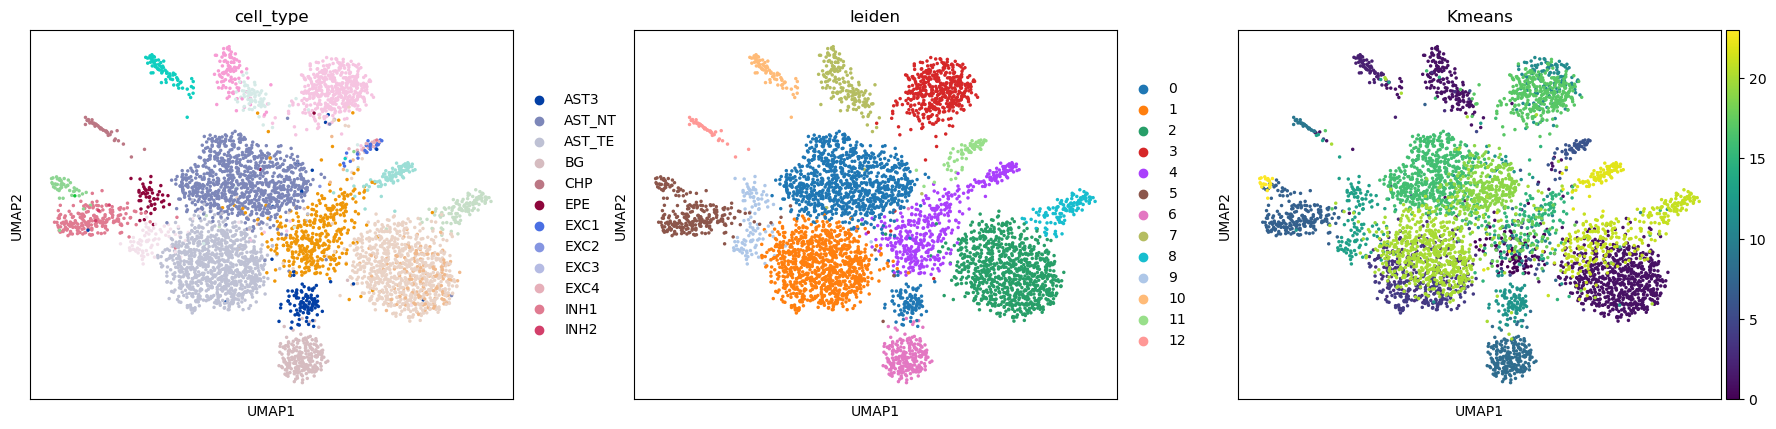

In [32]:
#visualize with umap all the clustering and the cell types

#H3K27ac

#original bin size
sc.pl.umap(H3K27ac_ad_filtered, color=['cell_type', 'leiden', 'Kmeans'])

#4x increased bins
sc.pl.umap(H3K27ac_4x_filt, color=['cell_type', 'leiden', 'Kmeans'])

#16x increased bins 
sc.pl.umap(H3K27ac_16x_filt, color=['cell_type', 'leiden', 'Kmeans'])

#H3K27me3

#original bin size
sc.pl.umap(H3K27me3_ad_filtered, color=['cell_type', 'leiden', 'Kmeans'])

#4x increased bins
sc.pl.umap(H3K27me3_4x_filt, color=['cell_type', 'leiden', 'Kmeans'])

#16x increased bins 
sc.pl.umap(H3K27me3_16x_filt, color=['cell_type', 'leiden', 'Kmeans'])

In [33]:
from test_clustering import NMI_ARI
#control the clustering results with the cell types (ARI and NMI)

#H3K27ac
print('Kmeans clustering :')
#original bin size
nmi_H3K27ac_orig, ari_H3K27ac_orig = NMI_ARI(H3K27ac_ad_filtered, clust='Kmeans')
print(f'NMI and ARI score for H3K27ac with original bin size (500bp) : \n - NMI = {nmi_H3K27ac_orig} \n - ARI = {ari_H3K27ac_orig}')
 
#4x increased bins
nmi_H3K27ac_4x, ari_H3K27ac_4x = NMI_ARI(H3K27ac_4x_filt, clust='Kmeans')
print(f'NMI and ARI score for H3K27ac with 4x bin size increase (2000bp) : \n - NMI = {nmi_H3K27ac_4x} \n - ARI = {ari_H3K27ac_4x}')

#16x increased bins
nmi_H3K27ac_16x, ari_H3K27ac_16x = NMI_ARI(H3K27ac_16x_filt, clust='Kmeans')
print(f'NMI and ARI score for H3K27ac with 16x bin size increase (8000bp) : \n - NMI = {nmi_H3K27ac_16x} \n - ARI = {ari_H3K27ac_16x}')

#H3K27me3

#original bin size
nmi_H3K27me3_orig, ari_H3K27me3_orig = NMI_ARI(H3K27me3_ad_filtered, clust='Kmeans')
print(f'NMI and ARI score for H3K27me3 with original bin size (500bp) : \n - NMI = {nmi_H3K27me3_orig} \n - ARI = {ari_H3K27me3_orig}')
 
#4x increased bins
nmi_H3K27me3_4x, ari_H3K27me3_4x = NMI_ARI(H3K27me3_4x_filt, clust='Kmeans')
print(f'NMI and ARI score for H3K27me3 with 4x bin size increase (2000bp) : \n - NMI = {nmi_H3K27me3_4x} \n - ARI = {ari_H3K27me3_4x}')

#16x increased bins
nmi_H3K27me3_16x, ari_H3K27me3_16x = NMI_ARI(H3K27me3_16x_filt, clust='Kmeans')
print(f'NMI and ARI score for H3K27me3 with 16x bin size increase (8000bp) : \n - NMI = {nmi_H3K27me3_16x} \n - ARI = {ari_H3K27me3_16x}')

Kmeans clustering :
NMI and ARI score for H3K27ac with original bin size (500bp) : 
 - NMI = 0.5362861494627372 
 - ARI = 0.3377091953719063
NMI and ARI score for H3K27ac with 4x bin size increase (2000bp) : 
 - NMI = 0.8059047121203087 
 - ARI = 0.5844647862923906
NMI and ARI score for H3K27ac with 16x bin size increase (8000bp) : 
 - NMI = 0.8271118960908385 
 - ARI = 0.5940431749951891
NMI and ARI score for H3K27me3 with original bin size (500bp) : 
 - NMI = 0.10630681884895929 
 - ARI = 0.05017192976191918
NMI and ARI score for H3K27me3 with 4x bin size increase (2000bp) : 
 - NMI = 0.5938530544849998 
 - ARI = 0.35259528817554886
NMI and ARI score for H3K27me3 with 16x bin size increase (8000bp) : 
 - NMI = 0.7315931680317178 
 - ARI = 0.5146708621619464


In [34]:
#H3K27ac
print('Leiden clustering :')
#original bin size
nmi_H3K27ac_orig, ari_H3K27ac_orig = NMI_ARI(H3K27ac_ad_filtered, clust='leiden')
print(f'NMI and ARI score for H3K27ac with original bin size (500bp) : \n - NMI = {nmi_H3K27ac_orig} \n - ARI = {ari_H3K27ac_orig}')
 
#4x increased bins
nmi_H3K27ac_4x, ari_H3K27ac_4x = NMI_ARI(H3K27ac_4x_filt, clust='leiden')
print(f'NMI and ARI score for H3K27ac with 4x bin size increase (2000bp) : \n - NMI = {nmi_H3K27ac_4x} \n - ARI = {ari_H3K27ac_4x}')

#16x increased bins
nmi_H3K27ac_16x, ari_H3K27ac_16x = NMI_ARI(H3K27ac_16x_filt, clust='leiden')
print(f'NMI and ARI score for H3K27ac with 16x bin size increase (8000bp) : \n - NMI = {nmi_H3K27ac_16x} \n - ARI = {ari_H3K27ac_16x}')

#H3K27me3

#original bin size
nmi_H3K27me3_orig, ari_H3K27me3_orig = NMI_ARI(H3K27me3_ad_filtered, clust='leiden')
print(f'NMI and ARI score for H3K27me3 with original bin size (500bp) : \n - NMI = {nmi_H3K27me3_orig} \n - ARI = {ari_H3K27me3_orig}')
 
#4x increased bins
nmi_H3K27me3_4x, ari_H3K27me3_4x = NMI_ARI(H3K27me3_4x_filt, clust='leiden')
print(f'NMI and ARI score for H3K27me3 with 4x bin size increase (2000bp) : \n - NMI = {nmi_H3K27me3_4x} \n - ARI = {ari_H3K27me3_4x}')

#16x increased bins
nmi_H3K27me3_16x, ari_H3K27me3_16x = NMI_ARI(H3K27me3_16x_filt, clust='leiden')
print(f'NMI and ARI score for H3K27me3 with 16x bin size increase (8000bp) : \n - NMI = {nmi_H3K27me3_16x} \n - ARI = {ari_H3K27me3_16x}')

Leiden clustering :


NMI and ARI score for H3K27ac with original bin size (500bp) : 
 - NMI = 0.5674881052696262 
 - ARI = 0.4689150384752608
NMI and ARI score for H3K27ac with 4x bin size increase (2000bp) : 
 - NMI = 0.8445500533815484 
 - ARI = 0.8092143173088296
NMI and ARI score for H3K27ac with 16x bin size increase (8000bp) : 
 - NMI = 0.9059529090269245 
 - ARI = 0.895336301429968
NMI and ARI score for H3K27me3 with original bin size (500bp) : 
 - NMI = 0.033278115721496575 
 - ARI = 0.010557755936360541
NMI and ARI score for H3K27me3 with 4x bin size increase (2000bp) : 
 - NMI = 0.6524966908227641 
 - ARI = 0.6536278741646642
NMI and ARI score for H3K27me3 with 16x bin size increase (8000bp) : 
 - NMI = 0.8560309711225779 
 - ARI = 0.8386874359931629


In [35]:
from test_clustering import ASW_LISI
#control the clustering results (ASW and LISI)

#H3K27ac
print('Kmeans clustering :')
#original bin size
asw_H3K27ac_orig, lisi_H3K27ac_orig = ASW_LISI(H3K27ac_ad_filtered, clust='Kmeans')
print(f'NMI and ARI score for H3K27ac with original bin size (500bp) : \n - ASW = {asw_H3K27ac_orig} \n - LISI = {lisi_H3K27ac_orig}')
 
#4x increased bins
asw_H3K27ac_4x, lisi_H3K27ac_4x = ASW_LISI(H3K27ac_4x_filt, clust='Kmeans')
print(f'NMI and ARI score for H3K27ac with 4x bin size increase (2000bp) : \n - ASW = {asw_H3K27ac_4x} \n - LISI = {lisi_H3K27ac_4x}')

#16x increased bins
asw_H3K27ac_16x, lisi_H3K27ac_16x = ASW_LISI(H3K27ac_16x_filt, clust='Kmeans')
print(f'NMI and ARI score for H3K27ac with 16x bin size increase (8000bp) : \n - ASW = {asw_H3K27ac_16x} \n - LISI = {lisi_H3K27ac_16x}')

#H3K27me3

#original bin size
asw_H3K27me3_orig, lisi_H3K27me3_orig = ASW_LISI(H3K27me3_ad_filtered, clust='Kmeans')
print(f'NMI and ARI score for H3K27me3 with original bin size (500bp) : \n - ASW = {asw_H3K27me3_orig} \n - LISI = {lisi_H3K27me3_orig}')
 
#4x increased bins
asw_H3K27me3_4x, lisi_H3K27me3_4x = ASW_LISI(H3K27me3_4x_filt, clust='Kmeans')
print(f'NMI and ARI score for H3K27me3 with 4x bin size increase (2000bp) : \n - ASW = {asw_H3K27me3_4x} \n - LISI = {lisi_H3K27me3_4x}')

#16x increased bins
asw_H3K27me3_16x, lisi_H3K27me3_16x = ASW_LISI(H3K27me3_16x_filt, clust='Kmeans')
print(f'NMI and ARI score for H3K27me3 with 16x bin size increase (8000bp) : \n - ASW = {asw_H3K27me3_16x} \n - LISI = {lisi_H3K27me3_16x}')

Kmeans clustering :
NMI and ARI score for H3K27ac with original bin size (500bp) : 
 - ASW = 0.4726787507534027 
 - LISI = 3.182788424804206
NMI and ARI score for H3K27ac with 4x bin size increase (2000bp) : 
 - ASW = 0.49160608649253845 
 - LISI = 2.369908551244364
NMI and ARI score for H3K27ac with 16x bin size increase (8000bp) : 
 - ASW = 0.4962223768234253 
 - LISI = 1.8844118977029516
NMI and ARI score for H3K27me3 with original bin size (500bp) : 
 - ASW = 0.46551966667175293 
 - LISI = 3.9647437064954563
NMI and ARI score for H3K27me3 with 4x bin size increase (2000bp) : 
 - ASW = 0.468915194272995 
 - LISI = 2.8666891451543592
NMI and ARI score for H3K27me3 with 16x bin size increase (8000bp) : 
 - ASW = 0.4879305064678192 
 - LISI = 1.8836171789584903


In [36]:
#H3K27ac
print('Leiden clustering :')
#original bin size
asw_H3K27ac_orig, lisi_H3K27ac_orig = ASW_LISI(H3K27ac_ad_filtered, clust='leiden')
print(f'NMI and ARI score for H3K27ac with original bin size (500bp) : \n - ASW = {asw_H3K27ac_orig} \n - LISI = {lisi_H3K27ac_orig}')
 
#4x increased bins
asw_H3K27ac_4x, lisi_H3K27ac_4x = ASW_LISI(H3K27ac_4x_filt, clust='leiden')
print(f'NMI and ARI score for H3K27ac with 4x bin size increase (2000bp) : \n - ASW = {asw_H3K27ac_4x} \n - LISI = {lisi_H3K27ac_4x}')

#16x increased bins
asw_H3K27ac_16x, lisi_H3K27ac_16x = ASW_LISI(H3K27ac_16x_filt, clust='leiden')
print(f'NMI and ARI score for H3K27ac with 16x bin size increase (8000bp) : \n - ASW = {asw_H3K27ac_16x} \n - LISI = {lisi_H3K27ac_16x}')

#H3K27me3

#original bin size
asw_H3K27me3_orig, lisi_H3K27me3_orig = ASW_LISI(H3K27me3_ad_filtered, clust='leiden')
print(f'NMI and ARI score for H3K27me3 with original bin size (500bp) : \n - ASW = {asw_H3K27me3_orig} \n - LISI = {lisi_H3K27me3_orig}')
 
#4x increased bins
asw_H3K27me3_4x, lisi_H3K27me3_4x = ASW_LISI(H3K27me3_4x_filt, clust='leiden')
print(f'NMI and ARI score for H3K27me3 with 4x bin size increase (2000bp) : \n - ASW = {asw_H3K27me3_4x} \n - LISI = {lisi_H3K27me3_4x}')

#16x increased bins
asw_H3K27me3_16x, lisi_H3K27me3_16x = ASW_LISI(H3K27me3_16x_filt, clust='leiden')
print(f'NMI and ARI score for H3K27me3 with 16x bin size increase (8000bp) : \n - ASW = {asw_H3K27me3_16x} \n - LISI = {lisi_H3K27me3_16x}')

Leiden clustering :
NMI and ARI score for H3K27ac with original bin size (500bp) : 
 - ASW = 0.46739524602890015 
 - LISI = 2.4734466840754328
NMI and ARI score for H3K27ac with 4x bin size increase (2000bp) : 
 - ASW = 0.5071438550949097 
 - LISI = 1.7392899092204224
NMI and ARI score for H3K27ac with 16x bin size increase (8000bp) : 
 - ASW = 0.5256069898605347 
 - LISI = 1.3439193453224019
NMI and ARI score for H3K27me3 with original bin size (500bp) : 
 - ASW = 0.49381962418556213 
 - LISI = 6.025649722117809
NMI and ARI score for H3K27me3 with 4x bin size increase (2000bp) : 
 - ASW = 0.5034365653991699 
 - LISI = 2.7546730549831016
NMI and ARI score for H3K27me3 with 16x bin size increase (8000bp) : 
 - ASW = 0.5072465538978577 
 - LISI = 1.5807056700901017


# Exploration is finished, now we can try to tune a little more the parameter

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Number of bins with more than 50 cells having non-zero values: 42440


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)
Exception in thread Thread-4 (_readerthread):
Traceback (most recent call last):
  File "c:\Users\yvanb\miniforge3\envs\MLCourse\lib\threading.py", line 1016, in _bootstrap_inner
    self.run()
  File "c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\ipykernel\ipkernel.py", line 772, in run_closure
    _threading_Thread_run(self)
  File "c:\Users\yvanb\miniforge3\envs\MLCourse\lib\threading.py", line 953, in run
    self._target(*self._args, **self._kwargs)
  File "c:\Users\yvanb\miniforge3\envs\MLCourse\lib\subprocess.py", line 1515, in _readerthread
    buffer.append(fh.read())
  File "c:\Users\yvanb\miniforge3\envs\MLCourse\lib\codecs.py", line 322, in decode
    (result, consumed) = self._buffer_decode(data, self.errors, final)
UnicodeDecodeError: 'utf-8' codec can't decode byte 0x82 in position 110: invalid 

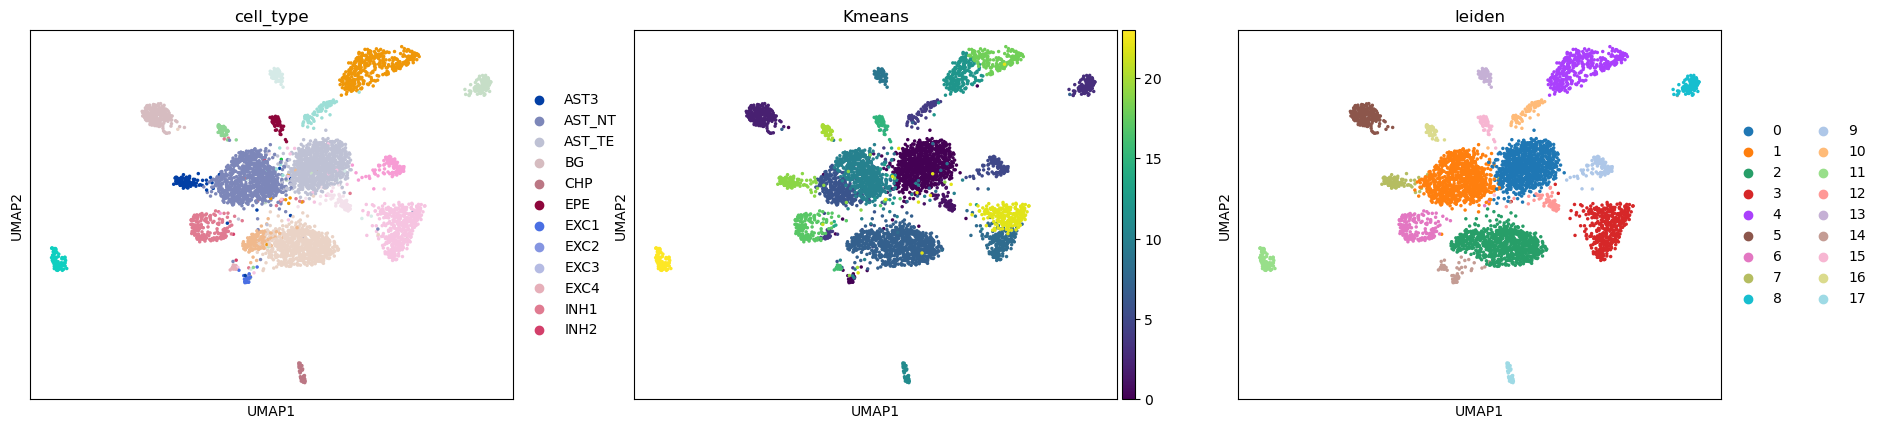

Clustering score for Kmeans :
 - NMI score : 0.875, ARI score : 0.780
 - ASW score : 0.540, LISI score (mean) : 1.355
Clustering score for leiden :
 - NMI score : 0.916, ARI score : 0.901
 - ASW score : 0.531, LISI score (mean) : 1.221


In [2]:
from dim_reduction import dim_red_pipeline
from clustering import clustering
from test_clustering import clust_score

#as we saw that increasing the bin size result in better score and visualization, try with a extrem increase

#testing with an increase size of 100x (only H3K27ac for now)
H3K27ac_100x = dim_red_pipeline(H3K27ac_ad, increase_bin=True, filtering=True, factor=100)

#clustering + visualization
clustering(H3K27ac_100x, visualization=True)

#clustering score 
#Kmeans
clust_scores_kmeans = clust_score(H3K27ac_100x)

#leiden
clust_score_leiden = clust_score(H3K27ac_100x, clust_name='leiden')


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Number of bins with more than 100 cells having non-zero values: 34721


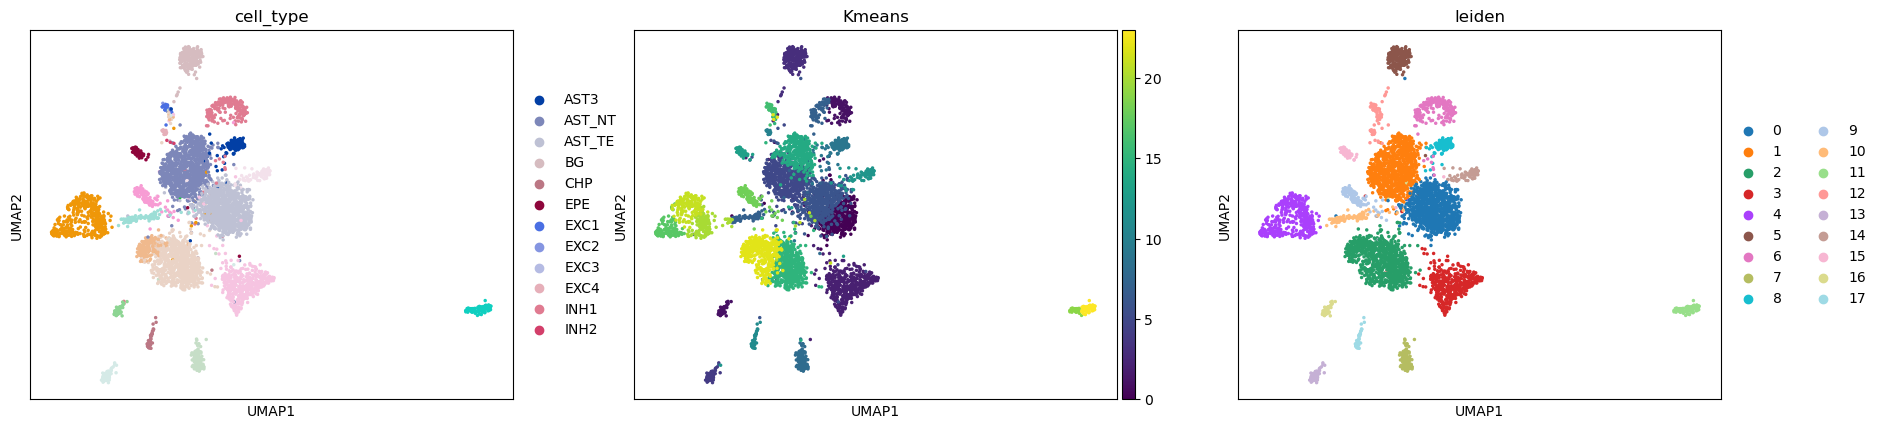

Clustering score for Kmeans :
 - NMI score : 0.838, ARI score : 0.657
 - ASW score : 0.519, LISI score (mean) : 1.611
Clustering score for leiden :
 - NMI score : 0.916, ARI score : 0.904
 - ASW score : 0.528, LISI score (mean) : 1.269


In [3]:
#if now we change the number of cells for the prevalance filtering
H3K27ac_100cells = dim_red_pipeline(H3K27ac_ad, increase_bin=True, filtering=True, nbre_cells=100, factor=100)

#clustering + visualization
clustering(H3K27ac_100cells, visualization=True)

#clustering score 
#Kmeans
clust_scores_kmeans = clust_score(H3K27ac_100cells)

#leiden
clust_score_leiden = clust_score(H3K27ac_100cells, clust_name='leiden')

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Number of bins with more than 20 cells having non-zero values: 47631


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


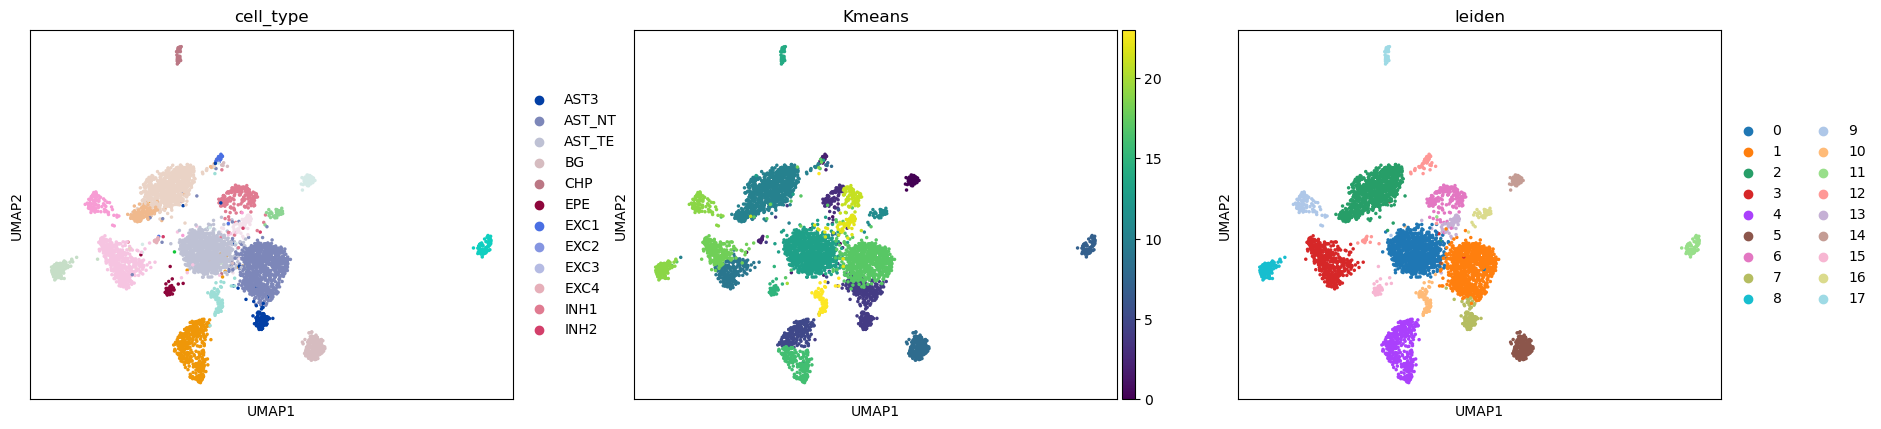

Clustering score for Kmeans :
 - NMI score : 0.871, ARI score : 0.800
 - ASW score : 0.543, LISI score (mean) : 1.303
Clustering score for leiden :
 - NMI score : 0.912, ARI score : 0.900
 - ASW score : 0.536, LISI score (mean) : 1.195


In [4]:
#smaller nbre of cells, less filtering
H3K27ac_20cells = dim_red_pipeline(H3K27ac_ad, increase_bin=True, filtering=True, nbre_cells=20, factor=100)

#clustering + visualization
clustering(H3K27ac_20cells, visualization=True)

#clustering score 
#Kmeans
clust_scores_kmeans = clust_score(H3K27ac_20cells)

#leiden
clust_score_leiden = clust_score(H3K27ac_20cells, clust_name='leiden')

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Number of bins with more than 50 cells having non-zero values: 42440


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


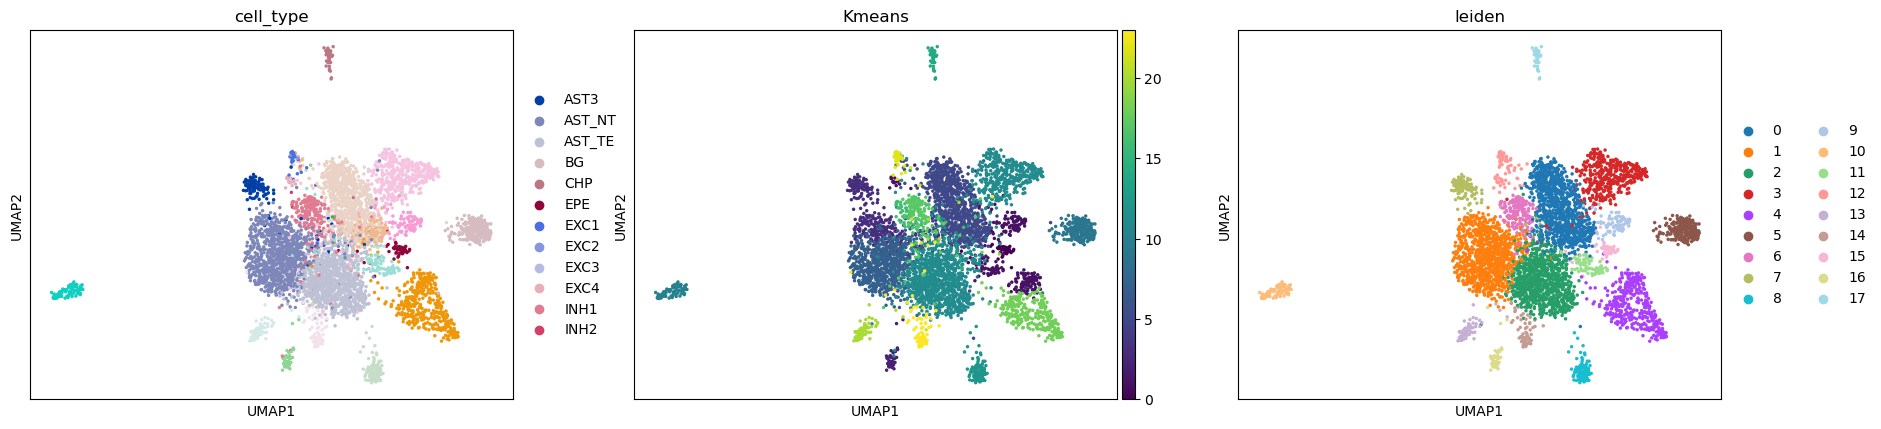

Clustering score for Kmeans :
 - NMI score : 0.821, ARI score : 0.667
 - ASW score : 0.481, LISI score (mean) : 1.765
Clustering score for leiden :
 - NMI score : 0.837, ARI score : 0.808
 - ASW score : 0.495, LISI score (mean) : 1.712


In [5]:
#and if we change the numbre of components
H3K27ac_100comp = dim_red_pipeline(H3K27ac_ad, increase_bin=True, filtering=True, factor=100, n_components=100)

#clustering + visualization
clustering(H3K27ac_100comp, visualization=True)

#clustering score 
#Kmeans
clust_scores_kmeans = clust_score(H3K27ac_100comp)

#leiden
clust_score_leiden = clust_score(H3K27ac_100comp, clust_name='leiden')

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Number of bins with more than 50 cells having non-zero values: 42440


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


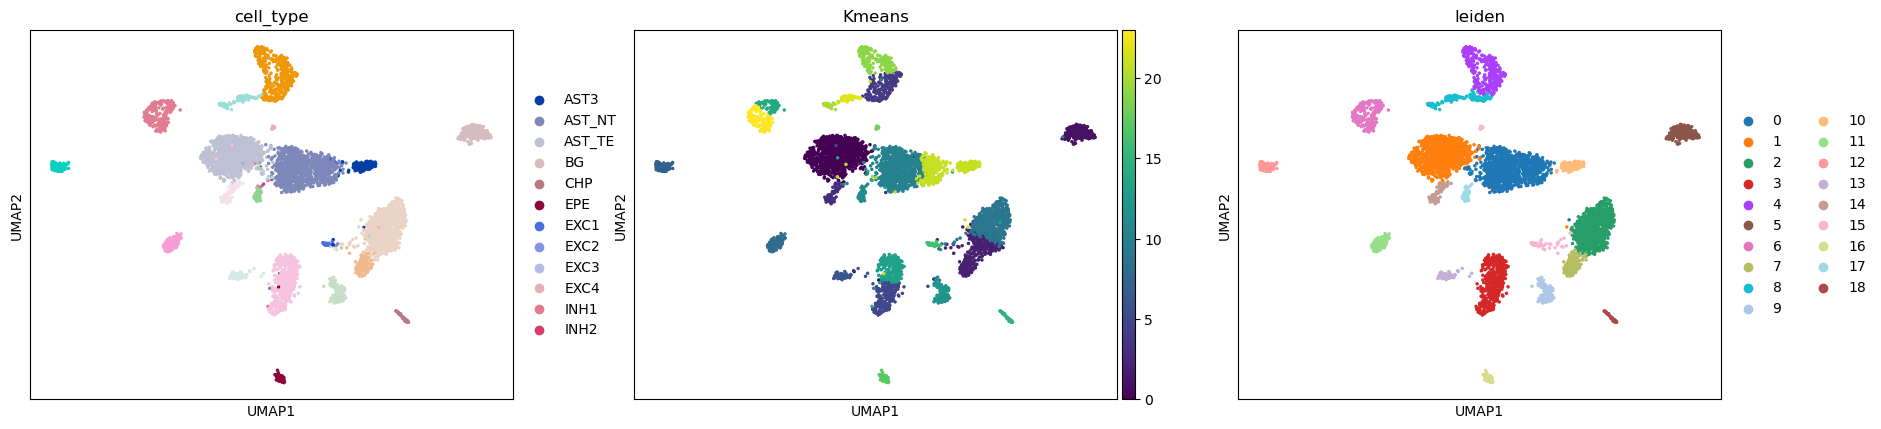

Clustering score for Kmeans :
 - NMI score : 0.872, ARI score : 0.779
 - ASW score : 0.628, LISI score (mean) : 1.189
Clustering score for leiden :
 - NMI score : 0.939, ARI score : 0.943
 - ASW score : 0.611, LISI score (mean) : 1.080


In [6]:
#now decrease the number of component
H3K27ac_25comp = dim_red_pipeline(H3K27ac_ad, increase_bin=True, filtering=True, factor=100, n_components=25)

#clustering + visualization
clustering(H3K27ac_25comp, visualization=True)

#clustering score 
#Kmeans
clust_scores_kmeans = clust_score(H3K27ac_25comp)

#leiden
clust_score_leiden = clust_score(H3K27ac_25comp, clust_name='leiden')

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Number of bins with more than 30 cells having non-zero values: 46245


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


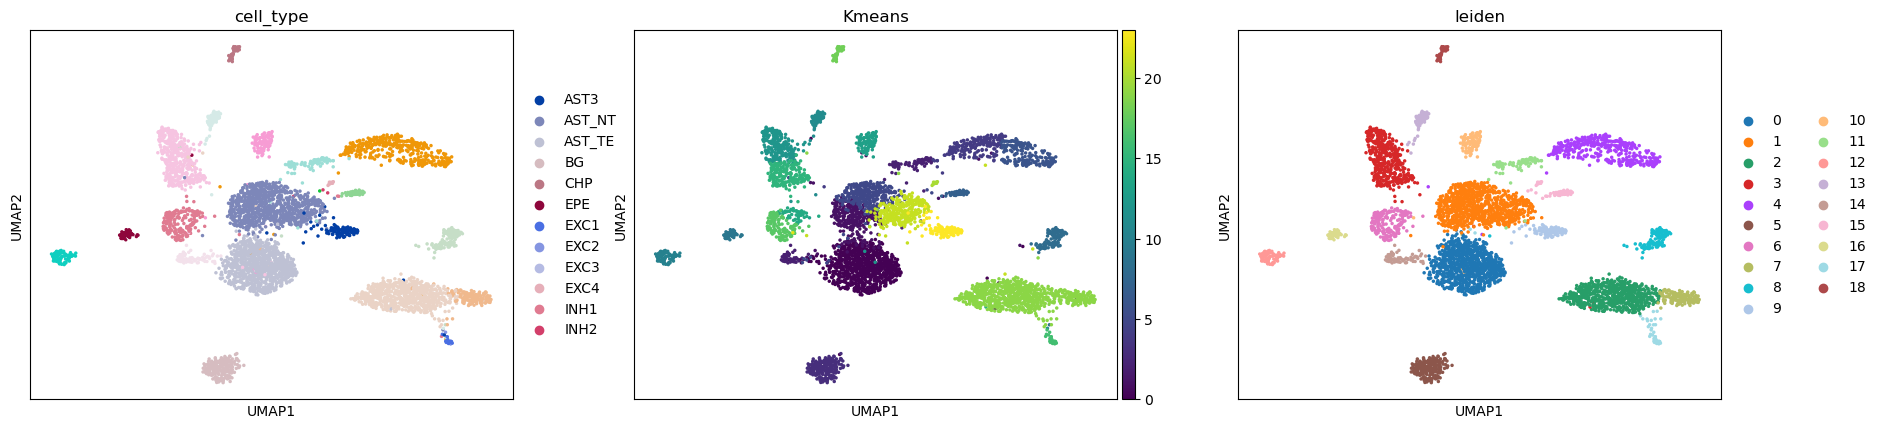

Clustering score for Kmeans :
 - NMI score : 0.855, ARI score : 0.734
 - ASW score : 0.605, LISI score (mean) : 1.250
Clustering score for leiden :
 - NMI score : 0.954, ARI score : 0.964
 - ASW score : 0.580, LISI score (mean) : 1.097


In [7]:
#so regrouping all these results, we have that increasing the size of the bins seems to result
#in better clustering and score, same it's visible when we decrease n_componenents and also a little
#when we decrease the nbre of cells for filtering.

#We can try to combine all this 
#increase bin size : 200, n_components = 30, nbre_cells = 30
H3K27ac_test = dim_red_pipeline(H3K27ac_ad, increase_bin=True, filtering=True, nbre_cells=30, factor=100, n_components=30)

#clustering + visualization
clustering(H3K27ac_test, visualization=True)

#clustering score 
#Kmeans
clust_scores_kmeans = clust_score(H3K27ac_test)

#leiden
clust_score_leiden = clust_score(H3K27ac_test, clust_name='leiden')

In [5]:
from dim_reduction import dim_red_pipeline
from clustering import clustering
from test_clustering import clust_score

#We can try to tune a little this code (appro 1 min per run so if we have 45 combinaisons, will take approx. 45 min)
#we will compare only with leiden (seems to have better results) and have less values for nbre_cells (seems to have the smallest effect)
def tuning_dim_red(anndata, nbre_cells, factors, n_components) :
    best_score = -np.inf
    best_params = [0, 0, 0]
    for cell in nbre_cells :
        for factor in factors :
            for comp in n_components :
                data = dim_red_pipeline(anndata, increase_bin=True, filtering=True, nbre_cells=cell, factor=factor, n_components=comp)
                clustering(data, Kmeans=False)
                scores = clust_score(data, clust_name='leiden')
                score_evaluation = np.mean(scores[:2]) - scores[3] #because NMI, ARI and ASW are between 0-1 and higher score means better one, and smaller LISI means better one
                print(f'Evaluation score for {cell} (nbre_cells), {factor} (factor), {comp} (n_component) : {score_evaluation:.3f}')
                if score_evaluation > best_score :
                    best_score = score_evaluation
                    best_params = [cell, factor, comp]
    print(f'Best score : {best_score}, with best parameters : {best_params}')
    return best_params
                

In [6]:
nbre_cells = [25, 50, 100]
factors = [10, 50, 100, 300, 500]
n_components = [10, 25, 50, 75]

best_params = tuning_dim_red(H3K27ac_ad, nbre_cells, factors, n_components)

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Number of bins with more than 25 cells having non-zero values: 208592


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Clustering score for leiden :
 - NMI score : 0.888, ARI score : 0.832
 - ASW score : 0.685, LISI score (mean) : 1.101
Evaluation score for 25 (nbre_cells), 10 (factor), 10 (n_component) : -0.241


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Number of bins with more than 25 cells having non-zero values: 208592


... (134 outputs left out)

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Number of bins with more than 100 cells having non-zero values: 9685
Clustering score for leiden :
 - NMI score : 0.907, ARI score : 0.908
 - ASW score : 0.499, LISI score (mean) : 1.366
Evaluation score for 100 (nbre_cells), 500 (factor), 50 (n_component) : -0.458


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Number of bins with more than 100 cells having non-zero values: 9685
Clustering score for leiden :
 - NMI score : 0.824, ARI score : 0.754
 - ASW score : 0.507, LISI score (mean) : 1.674
Evaluation score for 100 (nbre_cells), 500 (factor), 75 (n_component) : -0.885
Best score : -0.11955926193794353, with best parameters : [50, 300, 25]


In [8]:
#we can make the same things but we more precise values
nbre_cells = [50] #not so much impact so we will keep it at 50
factors = [150, 200, 250, 300, 350, 400, 450] #small is a less good, so will keep number between 100-500
n_components = [15, 20, 25, 30, 35, 40, 45] # higher value is bad, keep around 25 

best_params = tuning_dim_red(H3K27ac_ad, nbre_cells, factors, n_components)

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Number of bins with more than 50 cells having non-zero values: 30617
Clustering score for leiden :
 - NMI score : 0.940, ARI score : 0.941
 - ASW score : 0.709, LISI score (mean) : 1.058
Evaluation score for 50 (nbre_cells), 150 (factor), 15 (n_component) : -0.118


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Number of bins with more than 50 cells having non-zero values: 30617
Clustering score for leiden :
 - NMI score : 0.951, ARI score : 0.956
 - ASW score : 0.651, LISI score (mean) : 1.059
Evaluation score for 50 (nbre_cells), 150 (factor), 20 (n_component) : -0.106


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Number of bins with more than 50 cells having non-zero values: 30617
Clustering score for leiden :
 - NMI score : 0.926, ARI score : 0.873
 - ASW score : 0.608, LISI score (mean) : 1.108
Evaluation score for 50 (nbre_cells), 150 (factor), 25 (n_component) : -0.208


... (88 outputs left out)

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Number of bins with more than 50 cells having non-zero values: 10959
Clustering score for leiden :
 - NMI score : 0.909, ARI score : 0.874
 - ASW score : 0.541, LISI score (mean) : 1.193
Evaluation score for 50 (nbre_cells), 450 (factor), 40 (n_component) : -0.302


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Number of bins with more than 50 cells having non-zero values: 10959
Clustering score for leiden :
 - NMI score : 0.919, ARI score : 0.925
 - ASW score : 0.507, LISI score (mean) : 1.283
Evaluation score for 50 (nbre_cells), 450 (factor), 45 (n_component) : -0.361
Best score : -0.10567387342984713, with best parameters : [50, 150, 20]


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Number of bins with more than 50 cells having non-zero values: 30617


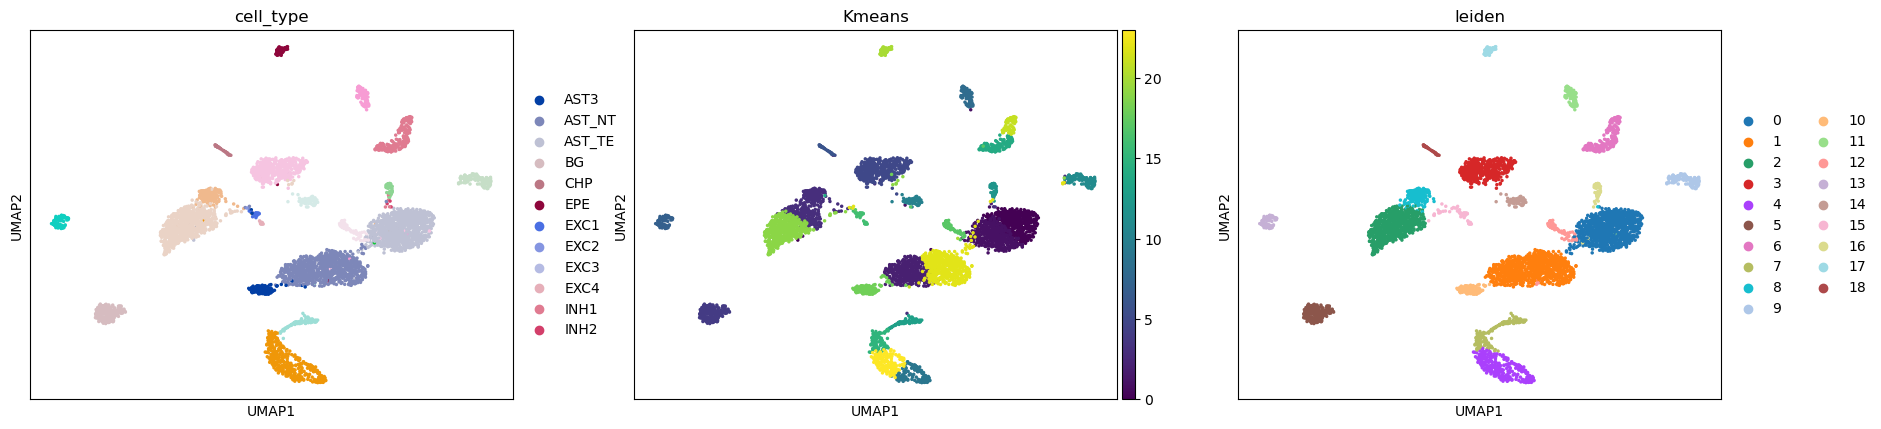

Clustering score for Kmeans :
 - NMI score : 0.855, ARI score : 0.660
 - ASW score : 0.639, LISI score (mean) : 1.222
Clustering score for leiden :
 - NMI score : 0.940, ARI score : 0.945
 - ASW score : 0.652, LISI score (mean) : 1.064


In [9]:
#we can try to see the result
H3K27ac_best_param = dim_red_pipeline(H3K27ac_ad, increase_bin=True, filtering=True, nbre_cells=best_params[0], factor=best_params[1], n_components=best_params[2])

#clustering + visualization
clustering(H3K27ac_best_param, visualization=True)

#clustering score 
#Kmeans
clust_scores_kmeans = clust_score(H3K27ac_best_param)

#leiden
clust_score_leiden = clust_score(H3K27ac_best_param, clust_name='leiden')

In [10]:
#can try the same tuning pipeline but for H3K27me3
nbre_cells = [25, 50, 100]
factors = [10, 50, 100, 300, 500]
n_components = [10, 25, 50, 75]

best_params_me3 = tuning_dim_red(H3K27me3_ad, nbre_cells, factors, n_components)

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Number of bins with more than 25 cells having non-zero values: 47595
Clustering score for leiden :
 - NMI score : 0.802, ARI score : 0.630
 - ASW score : 0.616, LISI score (mean) : 1.159
Evaluation score for 25 (nbre_cells), 10 (factor), 10 (n_component) : -0.443


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Number of bins with more than 25 cells having non-zero values: 47595
Clustering score for leiden :
 - NMI score : 0.884, ARI score : 0.883
 - ASW score : 0.559, LISI score (mean) : 1.158
Evaluation score for 25 (nbre_cells), 10 (factor), 25 (n_component) : -0.275


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Number of bins with more than 25 cells having non-zero values: 47595
Clustering score for leiden :
 - NMI score : 0.853, ARI score : 0.858
 - ASW score : 0.520, LISI score (mean) : 1.381
Evaluation score for 25 (nbre_cells), 10 (factor), 50 (n_component) : -0.525


... (118 outputs left out)

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Number of bins with more than 100 cells having non-zero values: 8005
Clustering score for leiden :
 - NMI score : 0.831, ARI score : 0.819
 - ASW score : 0.522, LISI score (mean) : 1.711
Evaluation score for 100 (nbre_cells), 500 (factor), 50 (n_component) : -0.886


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Number of bins with more than 100 cells having non-zero values: 8005
Clustering score for leiden :
 - NMI score : 0.696, ARI score : 0.640
 - ASW score : 0.511, LISI score (mean) : 2.199
Evaluation score for 100 (nbre_cells), 500 (factor), 75 (n_component) : -1.531
Best score : -0.1863702293616365, with best parameters : [50, 50, 25]


In [11]:
#we can make the same things but we more precise values
nbre_cells = [50] #not so much impact so we will keep it at 50
factors = [1, 25, 50, 75, 100, 125, 150, 175, 200] #small is a better, so will keep number between 1-200
n_components = [15, 20, 25, 30, 35, 40, 45] # higher value is bad, keep around 25 

best_params_me3 = tuning_dim_red(H3K27me3_ad, nbre_cells, factors, n_components)

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Number of bins with more than 50 cells having non-zero values: 10878


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Clustering score for leiden :
 - NMI score : 0.153, ARI score : 0.142
 - ASW score : 0.505, LISI score (mean) : 3.128
Evaluation score for 50 (nbre_cells), 1 (factor), 15 (n_component) : -2.980


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Number of bins with more than 50 cells having non-zero values: 10878


... (132 outputs left out)

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Number of bins with more than 50 cells having non-zero values: 18357
Clustering score for leiden :
 - NMI score : 0.908, ARI score : 0.906
 - ASW score : 0.531, LISI score (mean) : 1.344
Evaluation score for 50 (nbre_cells), 200 (factor), 40 (n_component) : -0.437


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Number of bins with more than 50 cells having non-zero values: 18357
Clustering score for leiden :
 - NMI score : 0.904, ARI score : 0.904
 - ASW score : 0.524, LISI score (mean) : 1.439
Evaluation score for 50 (nbre_cells), 200 (factor), 45 (n_component) : -0.534
Best score : -0.18313278703459224, with best parameters : [50, 75, 25]


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\muon\_atac\preproc.py:84: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Number of bins with more than 50 cells having non-zero values: 28792


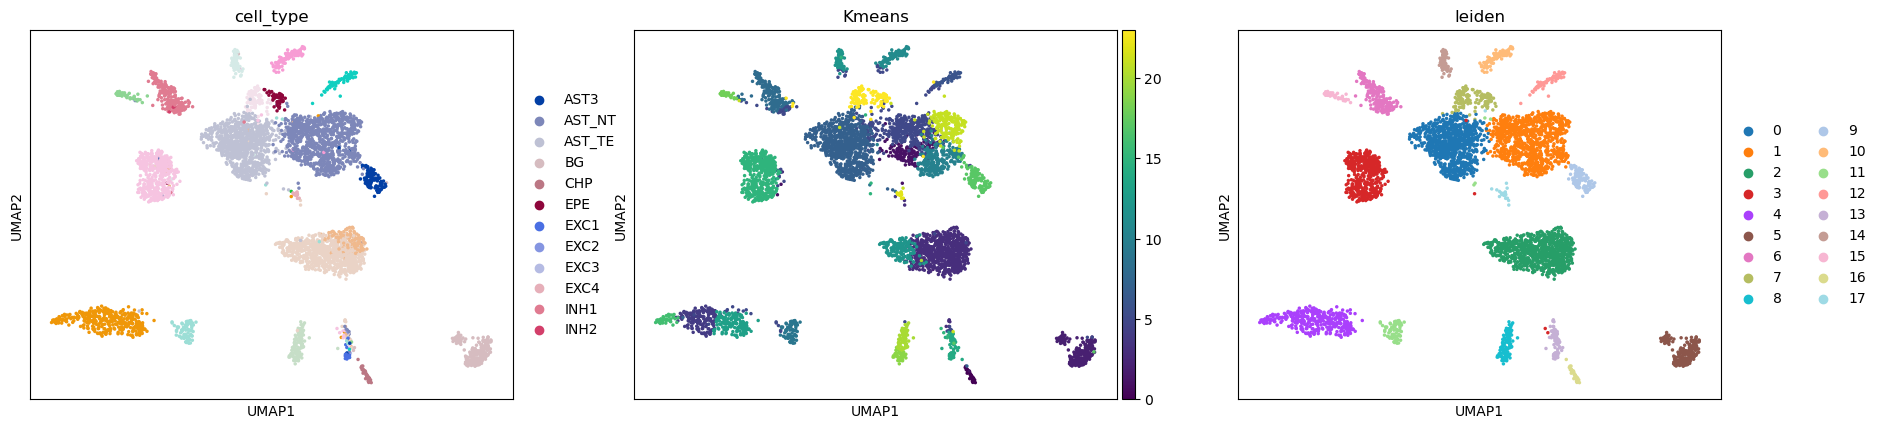

Clustering score for Kmeans :
 - NMI score : 0.791, ARI score : 0.651
 - ASW score : 0.583, LISI score (mean) : 1.305
Clustering score for leiden :
 - NMI score : 0.923, ARI score : 0.919
 - ASW score : 0.586, LISI score (mean) : 1.104


In [12]:
#we can try to see the result
H3K27me3_best_param = dim_red_pipeline(H3K27me3_ad, increase_bin=True, filtering=True, nbre_cells=best_params_me3[0], factor=best_params_me3[1], n_components=best_params_me3[2])

#clustering + visualization
clustering(H3K27me3_best_param, visualization=True)

#clustering score 
#Kmeans
clust_scores_kmeans = clust_score(H3K27me3_best_param)

#leiden
clust_score_leiden = clust_score(H3K27me3_best_param, clust_name='leiden')

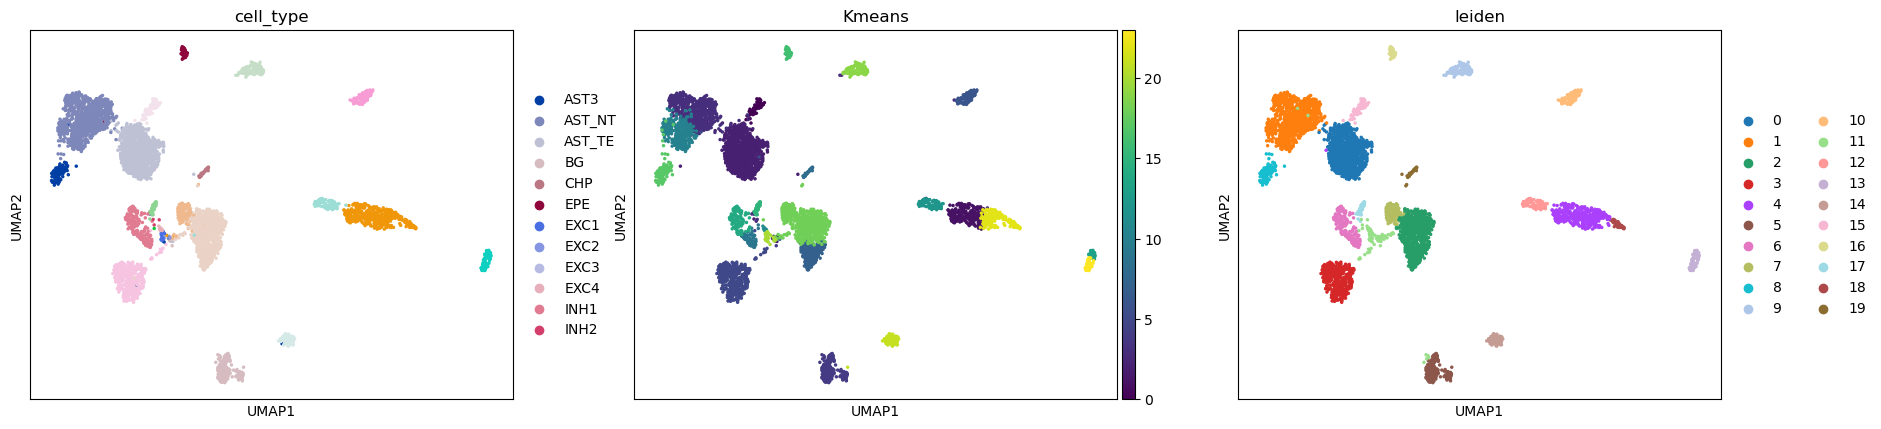

Clustering score for Kmeans :
 - NMI score : 0.892, ARI score : 0.786
 - ASW score : 0.622, LISI score (mean) : 1.151
Clustering score for leiden :
 - NMI score : 0.947, ARI score : 0.958
 - ASW score : 0.585, LISI score (mean) : 1.076


In [16]:
from clustering import clustering
#for fun concatenate the result of H3K27ac and H3K27me3 after dimension reduction
lsi_ac = H3K27ac_best_param.obsm['X_lsi']
lsi_me3 = H3K27me3_best_param.obsm['X_lsi']

ac_me3_merge = H3K27ac_best_param.copy()
ac_me3_merge.obsm['X_lsi'] = np.hstack([lsi_ac, lsi_me3])

clustering(ac_me3_merge, visualization=True,)

#clustering score 
#Kmeans
clust_scores_kmeans = clust_score(ac_me3_merge)

#leiden
clust_score_leiden = clust_score(ac_me3_merge, clust_name='leiden')